<a href="https://colab.research.google.com/github/ShamGaneshan2008/.ipynb-files-/blob/main/CIRCUITSCAN_DLL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
# CIRCUITSCAN AI
# Cell 1: Environment Setup

import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

# Make our experiments reproducible
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Choose GPU if available, otherwise use CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("CIRCUITSCAN AI")
print("-" * 35)

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. CPU mode is available.")

print("\nEnvironment setup complete!")

CIRCUITSCAN AI
-----------------------------------
PyTorch version: 2.11.0+cu130
NumPy version: 2.1.3
Selected device: cuda
GPU: Tesla T4

Environment setup complete!


In [31]:
# Cell 2: Create Dataset

import torch
from torch.utils.data import TensorDataset, DataLoader

# All possible single-digit addition problems
X = torch.tensor(
    [[a, b] for a in range(10) for b in range(10)],
    dtype=torch.long
)

y = X[:, 0] + X[:, 1]

# Split into training and testing data
train_mask = torch.rand(len(X)) < 0.8

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=16,
    shuffle=True
)

print("Total examples:", len(X))
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Sample input:", X[0].tolist())
print("Sample answer:", y[0].item())

Total examples: 100
Training examples: 78
Testing examples: 22
Sample input: [0, 0]
Sample answer: 0


In [32]:
# CIRCUITSCAN AI
# Cell 3: Prepare Model Inputs

VOCAB_SIZE = 10       # Digits 0 to 9
NUM_CLASSES = 19      # Possible sums: 0 to 18
SEQ_LENGTH = 2        # Two input numbers

# Move data to the selected device
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

print("Vocabulary size:", VOCAB_SIZE)
print("Possible answers:", NUM_CLASSES)
print("Input sequence length:", SEQ_LENGTH)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("\nInput example:", X_train[0].tolist())
print("Expected answer:", y_train[0].item())

Vocabulary size: 10
Possible answers: 19
Input sequence length: 2
Training data shape: torch.Size([78, 2])
Testing data shape: torch.Size([22, 2])

Input example: [0, 2]
Expected answer: 2


In [33]:
# CIRCUITSCAN AI
# Cell 4: Transformer Architecture

class CircuitScanTransformer(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(VOCAB_SIZE, 32)
        self.position = nn.Embedding(SEQ_LENGTH, 32)

        self.attention = nn.MultiheadAttention(
            embed_dim=32,
            num_heads=2,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(32)

        self.feed_forward = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32)
        )

        self.norm2 = nn.LayerNorm(32)
        self.classifier = nn.Linear(32, NUM_CLASSES)

    def forward(self, x):

        positions = torch.arange(
            SEQ_LENGTH, device=x.device
        ).unsqueeze(0)

        h = self.embedding(x) + self.position(positions)

        attention_output, attention_weights = self.attention(
            h, h, h,
            need_weights=True,
            average_attn_weights=False
        )

        h = self.norm1(h + attention_output)
        h = self.norm2(h + self.feed_forward(h))

        output = self.classifier(h.mean(dim=1))

        return output, attention_weights


model = CircuitScanTransformer().to(device)

print(model)
print("\nTotal trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

CircuitScanTransformer(
  (embedding): Embedding(10, 32)
  (position): Embedding(2, 32)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
  )
  (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (feed_forward): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
  )
  (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=32, out_features=19, bias=True)
)

Total trainable parameters: 9555


In [34]:
# CIRCUITSCAN AI
# Cell 5: Configure Training

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 100

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.001)
print("Training epochs:", EPOCHS)
print("\nTraining configuration complete!")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Training epochs: 100

Training configuration complete!


In [35]:
# CIRCUITSCAN AI
# Cell 6: Training Loop

loss_history = []

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        # Make predictions
        predictions, _ = model(inputs)

        # Calculate prediction error
        loss = criterion(predictions, targets)

        # Reset previous gradients
        optimizer.zero_grad()

        # Calculate new gradients
        loss.backward()

        # Update model parameters
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_history.append(average_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{EPOCHS} | "
            f"Loss: {average_loss:.4f}"
        )

print("\nTraining complete!")

Epoch  10/100 | Loss: 2.5591
Epoch  20/100 | Loss: 2.1488
Epoch  30/100 | Loss: 1.7222
Epoch  40/100 | Loss: 1.3751
Epoch  50/100 | Loss: 1.0830
Epoch  60/100 | Loss: 0.8011
Epoch  70/100 | Loss: 0.5661
Epoch  80/100 | Loss: 0.3768
Epoch  90/100 | Loss: 0.2499
Epoch 100/100 | Loss: 0.1677

Training complete!


In [36]:
# CIRCUITSCAN AI
# Cell 7: Evaluate Model

model.eval()

with torch.no_grad():

    predictions, attention_weights = model(X_test)

    predicted_answers = torch.argmax(predictions, dim=1)

    correct = (predicted_answers == y_test).sum().item()

    accuracy = correct / len(y_test) * 100

print("EVALUATION RESULTS")
print("-" * 35)
print("Test examples:", len(y_test))
print("Correct predictions:", correct)
print("Incorrect predictions:", len(y_test) - correct)
print(f"Accuracy: {accuracy:.2f}%")

EVALUATION RESULTS
-----------------------------------
Test examples: 22
Correct predictions: 0
Incorrect predictions: 22
Accuracy: 0.00%


In [37]:
# CIRCUITSCAN AI
# Cell 8: Diagnose Predictions

model.eval()

with torch.no_grad():
    predictions, _ = model(X_test)
    predicted_answers = predictions.argmax(dim=1)

print("PREDICTION DIAGNOSTICS")
print("-" * 45)

for i in range(min(10, len(X_test))):
    a, b = X_test[i].tolist()
    actual = y_test[i].item()
    predicted = predicted_answers[i].item()

    print(
        f"{a} + {b} = {actual} | "
        f"Model predicted: {predicted}"
    )

PREDICTION DIAGNOSTICS
---------------------------------------------
0 + 0 = 0 | Model predicted: 4
0 + 1 = 1 | Model predicted: 2
0 + 3 = 3 | Model predicted: 4
0 + 8 = 8 | Model predicted: 9
1 + 0 = 1 | Model predicted: 2
1 + 2 = 3 | Model predicted: 2
1 + 6 = 7 | Model predicted: 6
2 + 3 = 5 | Model predicted: 6
3 + 0 = 3 | Model predicted: 6
3 + 2 = 5 | Model predicted: 4


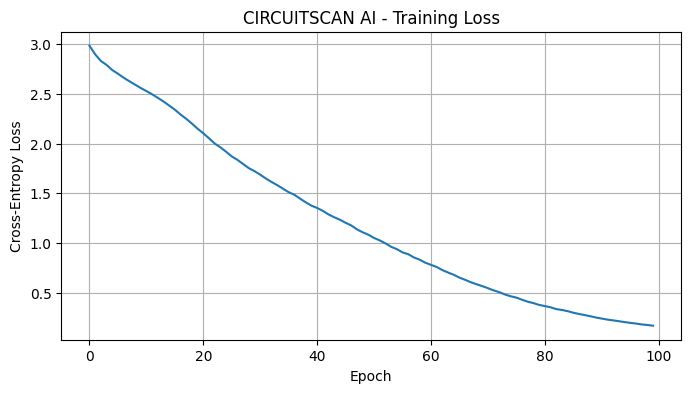

Initial loss: 2.9841
Final loss: 0.1677


In [38]:
# CIRCUITSCAN AI
# Cell 9: Training Loss Graph

plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.title("CIRCUITSCAN AI - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)

plt.show()

print("Initial loss:", round(loss_history[0], 4))
print("Final loss:", round(loss_history[-1], 4))

In [39]:
# CIRCUITSCAN AI
# Cell 10: Check Training Accuracy

model.eval()

with torch.no_grad():
    train_predictions, _ = model(X_train)
    train_answers = train_predictions.argmax(dim=1)

    train_correct = (train_answers == y_train).sum().item()
    train_accuracy = train_correct / len(y_train) * 100

print("TRAINING DIAGNOSTICS")
print("-" * 35)
print("Training examples:", len(y_train))
print("Correct predictions:", train_correct)
print(f"Training accuracy: {train_accuracy:.2f}%")
print(f"Test accuracy: {accuracy:.2f}%")

TRAINING DIAGNOSTICS
-----------------------------------
Training examples: 78
Correct predictions: 78
Training accuracy: 100.00%
Test accuracy: 0.00%


In [40]:
# CIRCUITSCAN AI
# Cell 11: Inspect Prediction Distribution

from collections import Counter

model.eval()

with torch.no_grad():
    test_logits, _ = model(X_test)
    test_answers = test_logits.argmax(dim=1).cpu().tolist()

actual_answers = y_test.cpu().tolist()

print("PREDICTED ANSWERS:")
print(Counter(test_answers).most_common())

print("\nACTUAL ANSWERS:")
print(Counter(actual_answers).most_common())

print("\nFIRST 10 TEST EXAMPLES:")
for i in range(min(10, len(X_test))):
    print(
        f"Input: {X_test[i].cpu().tolist()} | "
        f"Actual: {actual_answers[i]} | "
        f"Predicted: {test_answers[i]}"
    )

PREDICTED ANSWERS:
[(6, 5), (4, 3), (2, 3), (13, 3), (12, 2), (8, 2), (9, 1), (14, 1), (15, 1), (10, 1)]

ACTUAL ANSWERS:
[(3, 3), (8, 3), (7, 3), (12, 3), (1, 2), (5, 2), (0, 1), (10, 1), (13, 1), (9, 1), (16, 1), (15, 1)]

FIRST 10 TEST EXAMPLES:
Input: [0, 0] | Actual: 0 | Predicted: 4
Input: [0, 1] | Actual: 1 | Predicted: 2
Input: [0, 3] | Actual: 3 | Predicted: 4
Input: [0, 8] | Actual: 8 | Predicted: 9
Input: [1, 0] | Actual: 1 | Predicted: 2
Input: [1, 2] | Actual: 3 | Predicted: 2
Input: [1, 6] | Actual: 7 | Predicted: 6
Input: [2, 3] | Actual: 5 | Predicted: 6
Input: [3, 0] | Actual: 3 | Predicted: 6
Input: [3, 2] | Actual: 5 | Predicted: 4


In [41]:
# CIRCUITSCAN AI
# Cell 12: Manual Addition Test

examples = torch.tensor([
    [1, 1],
    [2, 2],
    [3, 4],
    [5, 5],
    [7, 2],
    [9, 9]
], dtype=torch.long, device=device)

model.eval()

with torch.no_grad():
    logits, _ = model(examples)
    answers = logits.argmax(dim=1)

print("MANUAL TEST")
print("-" * 40)

for pair, answer in zip(examples, answers):
    a, b = pair.tolist()
    predicted = answer.item()
    actual = a + b

    print(
        f"{a} + {b} | Expected: {actual} | "
        f"Predicted: {predicted} | "
        f"{'CORRECT' if predicted == actual else 'WRONG'}"
    )

MANUAL TEST
----------------------------------------
1 + 1 | Expected: 2 | Predicted: 2 | CORRECT
2 + 2 | Expected: 4 | Predicted: 4 | CORRECT
3 + 4 | Expected: 7 | Predicted: 7 | CORRECT
5 + 5 | Expected: 10 | Predicted: 10 | CORRECT
7 + 2 | Expected: 9 | Predicted: 8 | WRONG
9 + 9 | Expected: 18 | Predicted: 18 | CORRECT


In [42]:
# CIRCUITSCAN AI
# Cell 13: Check Training Exposure

examples = [
    (1, 1),
    (2, 2),
    (3, 4),
    (5, 5),
    (7, 2),
    (9, 9)
]

train_pairs = set(map(tuple, X_train.cpu().tolist()))
test_pairs = set(map(tuple, X_test.cpu().tolist()))

print("TRAINING EXPOSURE CHECK")
print("-" * 45)

for a, b in examples:
    pair = (a, b)

    if pair in train_pairs:
        status = "Seen during training"
    elif pair in test_pairs:
        status = "Held out for testing"
    else:
        status = "Not found in either split"

    print(f"{a} + {b}: {status}")

TRAINING EXPOSURE CHECK
---------------------------------------------
1 + 1: Seen during training
2 + 2: Seen during training
3 + 4: Seen during training
5 + 5: Seen during training
7 + 2: Held out for testing
9 + 9: Seen during training


In [43]:
# CIRCUITSCAN AI
# Cell 14: Generalization Check

model.eval()

with torch.no_grad():
    train_logits, _ = model(X_train)
    test_logits, _ = model(X_test)

    train_predictions = train_logits.argmax(dim=1)
    test_predictions = test_logits.argmax(dim=1)

    train_accuracy = (
        (train_predictions == y_train).float().mean().item() * 100
    )

    test_accuracy = (
        (test_predictions == y_test).float().mean().item() * 100
    )

    test_mae = (
        (test_predictions.float() - y_test.float()).abs().mean().item()
    )

print("GENERALIZATION REPORT")
print("-" * 40)
print(f"Training accuracy: {train_accuracy:.2f}%")
print(f"Test accuracy:     {test_accuracy:.2f}%")
print(f"Test MAE:          {test_mae:.2f}")

GENERALIZATION REPORT
----------------------------------------
Training accuracy: 100.00%
Test accuracy:     0.00%
Test MAE:          1.55


In [44]:
# CIRCUITSCAN AI
# Cell 15: Continue Training

EXTRA_EPOCHS = 200

for epoch in range(EXTRA_EPOCHS):

    model.train()
    total_loss = 0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions, _ = model(inputs)
        loss = criterion(predictions, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    if (epoch + 1) % 50 == 0:
        print(
            f"Extra Epoch {epoch + 1}/{EXTRA_EPOCHS} | "
            f"Loss: {total_loss / len(train_loader):.4f}"
        )

print("\nAdditional training complete!")

Extra Epoch 50/200 | Loss: 0.0410
Extra Epoch 100/200 | Loss: 0.0178
Extra Epoch 150/200 | Loss: 0.0100
Extra Epoch 200/200 | Loss: 0.0064

Additional training complete!


In [45]:
model.eval()

with torch.no_grad():
    predictions, _ = model(X_test.to(device))
    predicted_answers = predictions.argmax(dim=1).cpu()

print("TEST PREDICTION AUDIT")
print("-" * 45)

for i in range(len(X_test)):
    a = X_test[i][0].item()
    b = X_test[i][1].item()
    actual = y_test[i].item()
    predicted = predicted_answers[i].item()

    print(
        f"{a} + {b} = {actual} | "
        f"Predicted: {predicted} | "
        f"Error: {abs(actual - predicted)}"
    )

TEST PREDICTION AUDIT
---------------------------------------------
0 + 0 = 0 | Predicted: 4 | Error: 4
0 + 1 = 1 | Predicted: 2 | Error: 1
0 + 3 = 3 | Predicted: 4 | Error: 1
0 + 8 = 8 | Predicted: 9 | Error: 1
1 + 0 = 1 | Predicted: 2 | Error: 1
1 + 2 = 3 | Predicted: 2 | Error: 1
1 + 6 = 7 | Predicted: 9 | Error: 2
2 + 3 = 5 | Predicted: 6 | Error: 1
3 + 0 = 3 | Predicted: 6 | Error: 3
3 + 2 = 5 | Predicted: 7 | Error: 2
3 + 5 = 8 | Predicted: 7 | Error: 1
3 + 7 = 10 | Predicted: 12 | Error: 2
4 + 3 = 7 | Predicted: 6 | Error: 1
5 + 3 = 8 | Predicted: 6 | Error: 2
5 + 8 = 13 | Predicted: 10 | Error: 3
6 + 6 = 12 | Predicted: 13 | Error: 1
7 + 0 = 7 | Predicted: 8 | Error: 1
7 + 2 = 9 | Predicted: 8 | Error: 1
7 + 9 = 16 | Predicted: 15 | Error: 1
8 + 4 = 12 | Predicted: 9 | Error: 3
9 + 3 = 12 | Predicted: 10 | Error: 2
9 + 6 = 15 | Predicted: 16 | Error: 1


In [46]:
print("DATASET AUDIT")
print("-" * 40)

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))

print("\nFirst 10 training examples:")
for i in range(min(10, len(X_train))):
    a = X_train[i][0].item()
    b = X_train[i][1].item()
    answer = y_train[i].item()

    print(f"{a} + {b} = {answer}")

print("\nFirst 10 test examples:")
for i in range(min(10, len(X_test))):
    a = X_test[i][0].item()
    b = X_test[i][1].item()
    answer = y_test[i].item()

    print(f"{a} + {b} = {answer}")

print("\nLabel range:", y.min().item(), "to", y.max().item())
print("Output classes:", NUM_CLASSES)

DATASET AUDIT
----------------------------------------
Training examples: 78
Test examples: 22

First 10 training examples:
0 + 2 = 2
0 + 4 = 4
0 + 5 = 5
0 + 6 = 6
0 + 7 = 7
0 + 9 = 9
1 + 1 = 2
1 + 3 = 4
1 + 4 = 5
1 + 5 = 6

First 10 test examples:
0 + 0 = 0
0 + 1 = 1
0 + 3 = 3
0 + 8 = 8
1 + 0 = 1
1 + 2 = 3
1 + 6 = 7
2 + 3 = 5
3 + 0 = 3
3 + 2 = 5

Label range: 0 to 18
Output classes: 19


In [47]:
print("LABEL VALIDATION")
print("-" * 40)

errors = []

for i in range(len(X)):
    a = X[i][0].item()
    b = X[i][1].item()
    actual = y[i].item()
    expected = a + b

    if actual != expected:
        errors.append((a, b, actual, expected))

print("Total examples:", len(X))
print("Incorrect labels:", len(errors))

if errors:
    for error in errors:
        print(
            f"{error[0]} + {error[1]}: "
            f"label={error[2]}, expected={error[3]}"
        )
else:
    print("All labels correctly match a + b.")

LABEL VALIDATION
----------------------------------------
Total examples: 100
Incorrect labels: 0
All labels correctly match a + b.


In [48]:
model.eval()

with torch.no_grad():
    predictions, _ = model(X.to(device))
    predicted_answers = predictions.argmax(dim=1).cpu()

correct = (predicted_answers == y).sum().item()
total = len(y)

print("FULL DATASET EVALUATION")
print("-" * 40)
print("Correct predictions:", correct)
print("Total examples:", total)
print(f"Accuracy: {correct / total * 100:.2f}%")

FULL DATASET EVALUATION
----------------------------------------
Correct predictions: 78
Total examples: 100
Accuracy: 78.00%


In [49]:
# Cell 20: Generate a larger dataset

import torch

# Generate every pair from 0 to 19
numbers = torch.arange(20)

X_new = torch.cartesian_prod(numbers, numbers)

# Correct answer for each pair
y_new = X_new[:, 0] + X_new[:, 1]

print("NEW DATASET REPORT")
print("-" * 40)
print("Total examples:", len(X_new))
print("Input shape:", X_new.shape)
print("Output shape:", y_new.shape)
print("Minimum answer:", y_new.min().item())
print("Maximum answer:", y_new.max().item())

NEW DATASET REPORT
----------------------------------------
Total examples: 400
Input shape: torch.Size([400, 2])
Output shape: torch.Size([400])
Minimum answer: 0
Maximum answer: 38


In [50]:
# Cell 21: Split the dataset

from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

# Create a reproducible 80/20 split
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y_new,
    test_size=0.2,
    random_state=42
)

# Create training and testing datasets
train_dataset_new = TensorDataset(X_train_new, y_train_new)
test_dataset_new = TensorDataset(X_test_new, y_test_new)

# Create batches for training
train_loader_new = DataLoader(
    train_dataset_new,
    batch_size=32,
    shuffle=True
)

test_loader_new = DataLoader(
    test_dataset_new,
    batch_size=32,
    shuffle=False
)

print("DATA SPLIT REPORT")
print("-" * 40)
print("Training examples:", len(X_train_new))
print("Testing examples:", len(X_test_new))
print("Training batches:", len(train_loader_new))
print("Testing batches:", len(test_loader_new))

DATA SPLIT REPORT
----------------------------------------
Training examples: 320
Testing examples: 80
Training batches: 10
Testing batches: 3


In [51]:
# Cell 22: Updated Transformer model

import torch
import torch.nn as nn

VOCAB_SIZE = 20
NUM_CLASSES = 39
SEQ_LENGTH = 2

class CircuitScanTransformer(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(VOCAB_SIZE, 32)
        self.position = nn.Embedding(SEQ_LENGTH, 32)

        self.attention = nn.MultiheadAttention(
            embed_dim=32,
            num_heads=2,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(32)

        self.feed_forward = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32)
        )

        self.norm2 = nn.LayerNorm(32)
        self.classifier = nn.Linear(32, NUM_CLASSES)

    def forward(self, x):

        positions = torch.arange(
            SEQ_LENGTH,
            device=x.device
        ).unsqueeze(0)

        h = self.embedding(x) + self.position(positions)

        attention_output, attention_weights = self.attention(
            h, h, h,
            need_weights=True,
            average_attn_weights=False
        )

        h = self.norm1(h + attention_output)
        h = self.norm2(h + self.feed_forward(h))

        output = self.classifier(h.mean(dim=1))

        return output, attention_weights


model = CircuitScanTransformer().to(device)

print("Updated model created!")
print("Input vocabulary:", VOCAB_SIZE)
print("Output classes:", NUM_CLASSES)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Updated model created!
Input vocabulary: 20
Output classes: 39
Trainable parameters: 10535


In [52]:
# Cell 23: Configure training

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 300

print("TRAINING CONFIGURATION")
print("-" * 40)
print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate:", 0.001)
print("Training epochs:", EPOCHS)
print("Training examples:", len(train_dataset_new))
print("Testing examples:", len(test_dataset_new))

TRAINING CONFIGURATION
----------------------------------------
Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Training epochs: 300
Training examples: 320
Testing examples: 80


In [53]:
# Cell 24: Train the updated Transformer

training_losses = []

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    for inputs, targets in train_loader_new:

        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions, _ = model(inputs)

        loss = criterion(predictions, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader_new)
    training_losses.append(average_loss)

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {average_loss:.4f}"
        )

print("\nTraining complete!")


Epoch 25/300 | Loss: 2.4279
Epoch 50/300 | Loss: 1.4747
Epoch 75/300 | Loss: 0.6871
Epoch 100/300 | Loss: 0.2244
Epoch 125/300 | Loss: 0.0841
Epoch 150/300 | Loss: 0.0407
Epoch 175/300 | Loss: 0.0235
Epoch 200/300 | Loss: 0.0150
Epoch 225/300 | Loss: 0.0103
Epoch 250/300 | Loss: 0.0074
Epoch 275/300 | Loss: 0.0056
Epoch 300/300 | Loss: 0.0043

Training complete!


In [54]:
# Cell 25: Evaluate on unseen examples

model.eval()

correct = 0
total = 0
absolute_error = 0

with torch.no_grad():

    for inputs, targets in test_loader_new:

        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions, _ = model(inputs)
        predicted_answers = predictions.argmax(dim=1)

        correct += (predicted_answers == targets).sum().item()

        absolute_error += (
            (predicted_answers - targets).abs().sum().item()
        )

        total += targets.size(0)

test_accuracy = correct / total * 100
test_mae = absolute_error / total

print("GENERALIZATION REPORT")
print("-" * 40)
print("Test examples:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Test MAE: {test_mae:.2f}")

GENERALIZATION REPORT
----------------------------------------
Test examples: 80
Correct predictions: 52
Incorrect predictions: 28
Test accuracy: 65.00%
Test MAE: 0.79


In [55]:
# Cell 26: Inspect test predictions

model.eval()

with torch.no_grad():
    predictions, attention_weights = model(
        X_test_new.to(device)
    )

    predicted_answers = predictions.argmax(dim=1).cpu()

print("TEST PREDICTION AUDIT")
print("-" * 50)

for i in range(len(X_test_new)):
    a = X_test_new[i, 0].item()
    b = X_test_new[i, 1].item()
    actual = y_test_new[i].item()
    predicted = predicted_answers[i].item()

    if predicted != actual:
        print(
            f"{a} + {b} = {actual} | "
            f"Predicted: {predicted} | "
            f"Error: {abs(actual - predicted)}"
        )

TEST PREDICTION AUDIT
--------------------------------------------------
1 + 13 = 14 | Predicted: 19 | Error: 5
10 + 10 = 20 | Predicted: 18 | Error: 2
4 + 4 = 8 | Predicted: 5 | Error: 3
13 + 6 = 19 | Predicted: 20 | Error: 1
6 + 6 = 12 | Predicted: 11 | Error: 1
6 + 12 = 18 | Predicted: 17 | Error: 1
2 + 2 = 4 | Predicted: 10 | Error: 6
18 + 16 = 34 | Predicted: 30 | Error: 4
11 + 11 = 22 | Predicted: 20 | Error: 2
0 + 15 = 15 | Predicted: 14 | Error: 1
0 + 0 = 0 | Predicted: 1 | Error: 1
11 + 5 = 16 | Predicted: 17 | Error: 1
13 + 1 = 14 | Predicted: 19 | Error: 5
2 + 17 = 19 | Predicted: 20 | Error: 1
17 + 2 = 19 | Predicted: 20 | Error: 1
19 + 1 = 20 | Predicted: 19 | Error: 1
1 + 5 = 6 | Predicted: 9 | Error: 3
7 + 8 = 15 | Predicted: 14 | Error: 1
8 + 13 = 21 | Predicted: 23 | Error: 2
16 + 18 = 34 | Predicted: 30 | Error: 4
1 + 19 = 20 | Predicted: 19 | Error: 1
7 + 12 = 19 | Predicted: 14 | Error: 5
14 + 14 = 28 | Predicted: 24 | Error: 4
5 + 1 = 6 | Predicted: 5 | Error: 1
13

In [56]:
# Cell 27: Inspect attention weights

model.eval()

# Select one incorrect example
example_index = 0

example = X_test_new[example_index:example_index + 1].to(device)

with torch.no_grad():
    logits, attention_weights = model(example)

predicted = logits.argmax(dim=1).item()
a = example[0, 0].item()
b = example[0, 1].item()

print("ATTENTION INSPECTION")
print("-" * 40)
print(f"Input: {a} + {b}")
print("Correct answer:", a + b)
print("Predicted answer:", predicted)

print("\nAttention weights by head:")

weights = attention_weights[0].cpu()

for head in range(weights.shape[0]):
    print(f"\nHead {head + 1}:")
    print(weights[head])

ATTENTION INSPECTION
----------------------------------------
Input: 10 + 9
Correct answer: 19
Predicted answer: 19

Attention weights by head:

Head 1:
tensor([[0.0544, 0.9456],
        [0.3251, 0.6749]])

Head 2:
tensor([[0.9767, 0.0233],
        [0.9823, 0.0177]])


In [57]:
# Cell 27: Inspect attention weights

model.eval()

# Choose one test example
example = X_test_new[0:1].to(device)

with torch.no_grad():
    logits, attention_weights = model(example)

a = example[0, 0].item()
b = example[0, 1].item()
predicted = logits.argmax(dim=1).item()

print("INPUT:", a, "+", b)
print("CORRECT ANSWER:", a + b)
print("PREDICTED ANSWER:", predicted)

print("\nATTENTION WEIGHTS")

for head in range(attention_weights.shape[1]):
    print(f"\nHead {head + 1}:")
    print(attention_weights[0, head].cpu())


INPUT: 10 + 9
CORRECT ANSWER: 19
PREDICTED ANSWER: 19

ATTENTION WEIGHTS

Head 1:
tensor([[0.0544, 0.9456],
        [0.3251, 0.6749]])

Head 2:
tensor([[0.9767, 0.0233],
        [0.9823, 0.0177]])


In [58]:
# Cell 28: Test the effect of each attention head

model.eval()

example = X_test_new[0:1].to(device)

# Save the original attention output projection
original_weight = model.attention.out_proj.weight.detach().clone()
original_bias = model.attention.out_proj.bias.detach().clone()

# Normal prediction
with torch.no_grad():
    normal_logits, _ = model(example)

normal_prediction = normal_logits.argmax(dim=1).item()

print("INPUT:", example[0].tolist())
print("NORMAL PREDICTION:", normal_prediction)

print("\nHead dimensions:", 32 // 2)

print(
    "\nImportant limitation: PyTorch's built-in MultiheadAttention "
    "does not expose each head's output directly in this model."
)
print(
    "We need a small model change before we can disable "
    "one head correctly."
)

INPUT: [10, 9]
NORMAL PREDICTION: 19

Head dimensions: 16

Important limitation: PyTorch's built-in MultiheadAttention does not expose each head's output directly in this model.
We need a small model change before we can disable one head correctly.


In [59]:
# Cell 28: Expose individual attention heads

import torch
import torch.nn as nn
import torch.nn.functional as F

class InspectableAttention(nn.Module):
    def __init__(self, embed_dim=32, num_heads=2):
        super().__init__()

        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, disable_head=None):
        batch, seq_len, embed_dim = x.shape

        def split_heads(layer):
            return layer(x).view(
                batch, seq_len, self.num_heads, self.head_dim
            ).transpose(1, 2)

        Q = split_heads(self.q_proj)
        K = split_heads(self.k_proj)
        V = split_heads(self.v_proj)

        scores = Q @ K.transpose(-2, -1)
        scores = scores / (self.head_dim ** 0.5)
        weights = F.softmax(scores, dim=-1)

        head_outputs = weights @ V

        if disable_head is not None:
            head_outputs[:, disable_head, :, :] = 0

        combined = head_outputs.transpose(1, 2).contiguous()
        combined = combined.view(batch, seq_len, embed_dim)

        return self.out_proj(combined), weights, head_outputs


class CircuitScanTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(VOCAB_SIZE, 32)
        self.position = nn.Embedding(SEQ_LENGTH, 32)
        self.attention = InspectableAttention(32, 2)

        self.norm1 = nn.LayerNorm(32)
        self.feed_forward = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 32)
        )
        self.norm2 = nn.LayerNorm(32)
        self.classifier = nn.Linear(32, NUM_CLASSES)

    def forward(self, x, disable_head=None):
        positions = torch.arange(
            SEQ_LENGTH, device=x.device
        ).unsqueeze(0)

        h = self.embedding(x) + self.position(positions)

        attention_output, attention_weights, head_outputs = (
            self.attention(h, disable_head=disable_head)
        )

        h = self.norm1(h + attention_output)
        h = self.norm2(h + self.feed_forward(h))

        logits = self.classifier(h.mean(dim=1))

        return logits, attention_weights, head_outputs


model = CircuitScanTransformer().to(device)

print("Inspectable Transformer created.")
print("Attention heads:", model.attention.num_heads)
print("Head dimension:", model.attention.head_dim)
print("Individual head outputs are now accessible.")

Inspectable Transformer created.
Attention heads: 2
Head dimension: 16
Individual head outputs are now accessible.


In [60]:
# Cell 29: Retrain the inspectable model

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 300
training_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for inputs, targets in train_loader_new:
        inputs = inputs.to(device)
        targets = targets.to(device)

        logits, _, _ = model(inputs)
        loss = criterion(logits, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader_new)
    training_losses.append(average_loss)

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {average_loss:.4f}"
        )

print("\nRetraining complete!")

Epoch 50/300 | Loss: 1.5486
Epoch 100/300 | Loss: 0.2963
Epoch 150/300 | Loss: 0.0445
Epoch 200/300 | Loss: 0.0150
Epoch 250/300 | Loss: 0.0074
Epoch 300/300 | Loss: 0.0042

Retraining complete!


In [61]:
# Cell 30: Test the causal effect of each attention head

model.eval()

# Use the same 80 test examples for every comparison
X_eval = X_test_new.to(device)
y_eval = y_test_new.to(device)

def evaluate_with_head_disabled(disable_head=None):
    correct = 0
    total = len(y_eval)

    with torch.no_grad():
        for start in range(0, total, 32):
            inputs = X_eval[start:start + 32]
            targets = y_eval[start:start + 32]

            logits, _, _ = model(
                inputs,
                disable_head=disable_head
            )

            predictions = logits.argmax(dim=1)
            correct += (predictions == targets).sum().item()

    return correct / total * 100

normal_accuracy = evaluate_with_head_disabled()
head1_accuracy = evaluate_with_head_disabled(disable_head=0)
head2_accuracy = evaluate_with_head_disabled(disable_head=1)

print("CAUSAL INTERVENTION REPORT")
print("-" * 45)
print(f"Normal test accuracy: {normal_accuracy:.2f}%")
print(f"Head 1 disabled:      {head1_accuracy:.2f}%")
print(f"Head 2 disabled:      {head2_accuracy:.2f}%")

print("\nAccuracy changes relative to normal:")

print(f"Head 1 effect: {head1_accuracy - normal_accuracy:+.2f} percentage points")
print(f"Head 2 effect: {head2_accuracy - normal_accuracy:+.2f} percentage points")

CAUSAL INTERVENTION REPORT
---------------------------------------------
Normal test accuracy: 65.00%
Head 1 disabled:      7.50%
Head 2 disabled:      8.75%

Accuracy changes relative to normal:
Head 1 effect: -57.50 percentage points
Head 2 effect: -56.25 percentage points
